In [ ]:
!pip install -q transformers torchaudio librosa scikit-learn seaborn tqdm

In [ ]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2ForSequenceClassification

model_name = "superb/wav2vec2-base-superb-er"

feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(model_name)
model = Wav2Vec2ForSequenceClassification.from_pretrained(model_name)

model.to(device)
model.eval()

print("Labels:", model.config.id2label)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/216 [00:00<?, ?it/s]

Labels: {0: 'neu', 1: 'hap', 2: 'ang', 3: 'sad'}


In [ ]:
DATASET_PATH = "/content/drive/MyDrive/Datasets/IESC_Hindi"

In [ ]:
import os

# Map IESC emotions to model emotions
emotion_map = {
    "anger": "ang",
    "happy": "hap",
    "neutral": "neu",
    "sad": "sad"
}

audio_paths = []
labels = []

for actor in os.listdir(DATASET_PATH):
    actor_path = os.path.join(DATASET_PATH, actor)

    if os.path.isdir(actor_path):

        for session in os.listdir(actor_path):
            session_path = os.path.join(actor_path, session)

            if os.path.isdir(session_path):

                for emotion in os.listdir(session_path):
                    emotion_path = os.path.join(session_path, emotion)

                    if emotion.lower() in emotion_map:
                        for file in os.listdir(emotion_path):
                            if file.endswith(".wav"):
                                audio_paths.append(os.path.join(emotion_path, file))
                                labels.append(emotion_map[emotion.lower()])

print("Total samples loaded:", len(audio_paths))

Total samples loaded: 1600


In [ ]:
print(model.config.label2id)

{'ang': 2, 'hap': 1, 'neu': 0, 'sad': 3}


In [ ]:
label2id = model.config.label2id
id2label = model.config.id2label

y_true = [label2id[label] for label in labels]

In [ ]:
import librosa
from tqdm import tqdm

y_pred = []

for path in tqdm(audio_paths):
    speech, sr = librosa.load(path, sr=16000)

    inputs = feature_extractor(
        speech,
        sampling_rate=16000,
        return_tensors="pt",
        padding=True
    )

    input_values = inputs.input_values.to(device)

    with torch.no_grad():
        logits = model(input_values).logits

    predicted_id = torch.argmax(logits, dim=-1).item()
    y_pred.append(predicted_id)

100%|██████████| 1600/1600 [17:16<00:00,  1.54it/s]


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=[id2label[i] for i in range(len(id2label))]
))

              precision    recall  f1-score   support

         neu       0.36      0.23      0.28       400
         hap       0.46      0.24      0.32       400
         ang       0.43      0.81      0.56       400
         sad       0.50      0.47      0.49       400

    accuracy                           0.44      1600
   macro avg       0.44      0.44      0.41      1600
weighted avg       0.44      0.44      0.41      1600



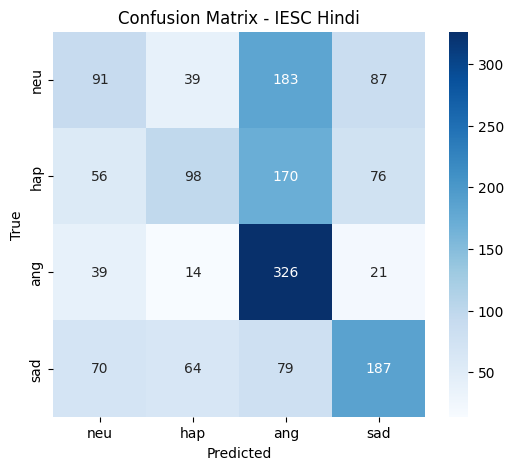

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cccm )
)
)

= confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            xticklabels=id2label.values(),
            yticklabels=id2label.values(),
            cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - IESC Hindi")
plt.show()